In [73]:
import pandas as pd
import matplotlib.pyplot as plt

df_pedidos = pd.read_csv("3.11 - Status Wave + oLPN.csv", sep='\t', encoding='utf-16')

df_pedidos.head(10)

,Filial,Data do Pedido,Tipo de pedido,Wave,Data locação pedido,Shipment,Filial Destino,Pedido,Status Pedido,Pedido de Venda,...,Status oLPN,Numero da Gaiola,BOX,Marcação de EAD,Data Prevista Entrega,Data Limite Expedição,Inventory Type ID,Cod Setor Item,Desc Setor Item,Audit Status
0,1200,2025-05-23 00:21:16,S39 - EXPEDICAO LEVES,W05232025000000000022,2025-05-23 00:22:47,87101095.0,1200,654910003,8000 - Enviada,277403082,...,Shipped,1045403.0,871,NaN,2025-05-23,2025-05-23,1200,22,UTILIDADES DOMESTICAS,NaN
1,1200,2025-05-23 00:21:17,S39R - SINGLE LINE,W05232025000000000024,2025-05-23 00:24:32,87101095.0,1200,654910002,8000 - Enviada,277403068,...,Shipped,1045394.0,871,NaN,2025-05-23,2025-05-23,1200,21,PORTATEIS,NaN
2,1200,2025-05-23 00:21:17,S39 - EXPEDICAO LEVES,W05232025000000000022,2025-05-23 00:22:47,87101095.0,1200,654910001,8000 - Enviada,277402881,...,Shipped,1045394.0,871,NaN,2025-05-23,2025-05-23,1200,21,PORTATEIS,NaN
3,1200,2025-05-23 00:21:17,S39 - EXPEDICAO LEVES,W05232025000000000022,2025-05-23 00:22:47,87101095.0,1200,654910004,8000 - Enviada,277403208,...,Shipped,1045394.0,871,NaN,2025-05-23,2025-05-23,1200,22,UTILIDADES DOMESTICAS,NaN
4,1200,2025-05-23 00:21:17,S39 - EXPEDICAO LEVES,W05232025000000000022,2025-05-23 00:22:47,87101095.0,1200,654910005,8000 - Enviada,277403454,...,Shipped,1045394.0,871,NaN,2025-05-23,2025-05-23,1200,21,PORTATEIS,NaN
5,1200,2025-05-23 00:21:18,S39 - EXPEDICAO LEVES,W05232025000000000022,2025-05-23 00:22:47,87101095.0,1200,654910006,8000 - Enviada,277403608,...,Shipped,1045394.0,871,NaN,2025-05-23,2025-05-23,1200,21,PORTATEIS,NaN
6,1200,2025-05-23 00:21:18,S39 - EXPEDICAO LEVES,W05232025000000000022,2025-05-23 00:22:47,87101095.0,1200,654910007,8000 - Enviada,277403711,...,Shipped,1045394.0,871,NaN,2025-05-23,2025-05-23,1200,46,BELEZA E SAUDE,NaN
7,1200,2025-05-23 00:21:18,S39 - EXPEDICAO LEVES,W05232025000000000022,2025-05-23 00:22:47,87101095.0,1200,654910009,8000 - Enviada,277404098,...,Shipped,1045394.0,871,NaN,2025-05-23,2025-05-23,1200,46,BELEZA e SAUDE,NaN
8,1200,2025-05-23 00:21:18,S39 - EXPEDICAO LEVES,W05232025000000000022,2025-05-23 00:22:47,87002493.0,1200,654910008,8000 - Enviada,277404071,...,Shipped,1037740.0,871,NaN,2025-05-23,2025-05-23,1200,11,AUDIO,NaN
9,1200,2025-05-23 00:21:18,S39 - EXPEDICAO LEVES,W05232025000000000022,2025-05-23 00:22:47,87101095.0,1200,654910010,8000 - Enviada,277404340,...,Shipped,1045394.0,871,NaN,2025-05-23,2025-05-23,1200,21,PORTATEIS,NaN


In [74]:
print(df_pedidos.shape)
df_pedidos.info()

(15820, 31)
<class 'pandas.DataFrame'>
RangeIndex: 15820 entries, 0 to 15819
Data columns (total 31 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Filial                 15820 non-null  int64  
 1   Data do Pedido         15820 non-null  str    
 2   Tipo de pedido         15820 non-null  str    
 3   Wave                   15820 non-null  str    
 4   Data locação pedido    15808 non-null  str    
 5   Shipment               15525 non-null  float64
 6   Filial Destino         15820 non-null  int64  
 7   Pedido                 15820 non-null  int64  
 8   Status Pedido          15820 non-null  str    
 9   Pedido de Venda        15820 non-null  str    
 10  oLPN                   15820 non-null  str    
 11  Último Update oLPN     15820 non-null  str    
 12  TOTE                   6234 non-null   str    
 13  Tarefa                 13829 non-null  str    
 14  Tarefa Status          13829 non-null  str    
 15  G

In [75]:
# Quais tipos de pedido estão associados à geração de TOTE e em qual proporção?
df_pedidos.groupby(['Tipo de pedido', df_pedidos['TOTE'].notna()]).size().unstack(fill_value=0)

TOTE,False,True
Tipo de pedido,,
S01 - ENTREGA A CLIENTES,1390,1189
S02 - RETIRA CLIENTE DEPOSITO,0,1
S04 - TRANSF EAD AUTOMATICA,0,111
S05 - TRANSF EAD PROGRAMADA,647,1156
S13 - ABASTECIMENTO DE LOJA BOA,6569,1925
S14 - ABASTECIMENTO DE LOJA QEB,1,0
S39 - EXPEDICAO LEVES,460,1547
S39I - EXPEDICAO LEVES,0,6
S39M - EXPEDICAO LEVES,55,59


In [76]:
resumo_tote = (
    df_pedidos.groupby('Tipo de pedido').agg(
        Total_registros=('TOTE', 'size'),
        Registros_com_tote=('TOTE', 'count')
    )
)
resumo_tote['Percentual_com_tote'] = (
    resumo_tote['Registros_com_tote'] /
    resumo_tote['Total_registros'] * 100
).round(2)

display(resumo_tote.sort_values('Percentual_com_tote', ascending=False))

,Total_registros,Registros_com_tote,Percentual_com_tote
Tipo de pedido,,,
S02 - RETIRA CLIENTE DEPOSITO,1,1,100.00
S04 - TRANSF EAD AUTOMATICA,111,111,100.00
S39I - EXPEDICAO LEVES,6,6,100.00
S39P - EXPEDICAO LEVES,3,3,100.00
S39 - EXPEDICAO LEVES,2007,1547,77.08
S39R - SINGLE LINE,168,111,66.07
S05 - TRANSF EAD PROGRAMADA,1803,1156,64.12
S39M - EXPEDICAO LEVES,114,59,51.75
S01 - ENTREGA A CLIENTES,2579,1189,46.10


In [77]:
resumo_tote =(
    df_pedidos[df_pedidos["TOTE"].notna() & df_pedidos["TOTE"].ne("")]
    .groupby("Tipo de pedido")["TOTE"]
    .nunique()
    .sort_values(ascending=True)
)
display(resumo_tote)

Tipo de pedido
S02 - RETIRA CLIENTE DEPOSITO         1
S39P - EXPEDICAO LEVES                2
S39I - EXPEDICAO LEVES                5
S46 - ABASTECIMENTO RETIRA LOJA      19
S39M - EXPEDICAO LEVES               23
S39R - SINGLE LINE                   53
S04 - TRANSF EAD AUTOMATICA          79
S53 - TRANSFERENCIA ENTRE CDS        89
S39 - EXPEDICAO LEVES               132
S13 - ABASTECIMENTO DE LOJA BOA     229
S01 - ENTREGA A CLIENTES            679
S05 - TRANSF EAD PROGRAMADA        1156
Name: TOTE, dtype: int64

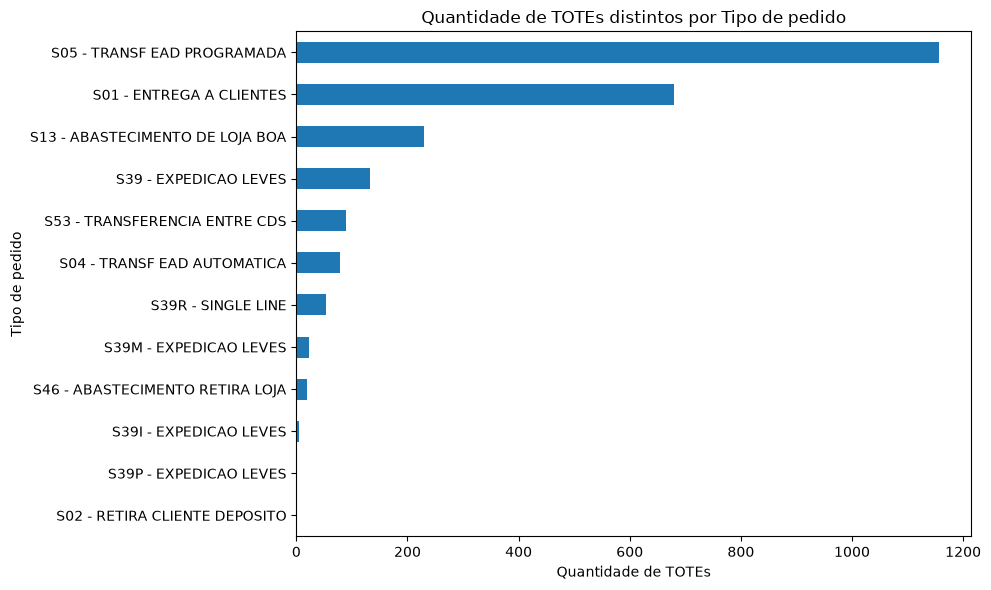

In [78]:
resumo_tote.plot(kind="barh", figsize=(10, 6))
plt.title("Quantidade de TOTEs distintos por Tipo de pedido")
plt.xlabel("Quantidade de TOTEs")
plt.ylabel("Tipo de pedido")
plt.tight_layout()
plt.show()

In [79]:
s05 = df_pedidos[df_pedidos["Tipo de pedido"] == "S05 - TRANSF EAD PROGRAMADA"]

display(
    s05.groupby(["Tarefa Status", "Grupo de Tarefa"], dropna=False).agg(
        Registros=("Pedido", "size"),
        TOTEs=("TOTE", "nunique")
    )
    .sort_values("TOTEs", ascending=True)
)

Registros  TOTEs
Tarefa Status        Grupo de Tarefa                  
Ready For Assignment SISTTK                 631      0
In Progress          SISTTK                   7      0
NaN                  NaN                      9      0
Completed            CEMP_03                  1      1
                     SISTTK                1155   1155

In [80]:

comparativo = df_pedidos.groupby("Tipo de pedido").agg(
    Registros=("Pedido", "size"),
    Pedidos_unicos=("Pedido", "nunique"),
    TOTEs_unicos=("TOTE", "nunique"),
    Registros_com_tarefa=("Tarefa", "count"),
    Registros_sem_tarefa=("Tarefa", lambda s: s.isna().sum())
)

display(comparativo.sort_values("TOTEs_unicos", ascending=False))


,Registros,Pedidos_unicos,TOTEs_unicos,Registros_com_tarefa,Registros_sem_tarefa
Tipo de pedido,,,,,
S05 - TRANSF EAD PROGRAMADA,1803,1663,1156,1794,9
S01 - ENTREGA A CLIENTES,2579,2091,679,1272,1307
S13 - ABASTECIMENTO DE LOJA BOA,8494,8374,229,8085,409
S39 - EXPEDICAO LEVES,2007,2007,132,1992,15
S53 - TRANSFERENCIA ENTRE CDS,291,11,89,103,188
S04 - TRANSF EAD AUTOMATICA,111,80,79,111,0
S39R - SINGLE LINE,168,69,53,168,0
S39M - EXPEDICAO LEVES,114,49,23,59,55
S46 - ABASTECIMENTO RETIRA LOJA,242,242,19,234,8


In [81]:

display(
    df_pedidos.groupby(["Tipo de pedido", "Grupo de Tarefa"], dropna=False)
    .agg(
        Registros=("Pedido", "size"),
        TOTEs=("TOTE", "nunique")
    )
    .query("`Grupo de Tarefa` == 'SISTTK'")
    .sort_values("TOTEs", ascending=False)
)


,,Registros,TOTEs
Tipo de pedido,Grupo de Tarefa,,
S05 - TRANSF EAD PROGRAMADA,SISTTK,1793,1155
S01 - ENTREGA A CLIENTES,SISTTK,682,601
S53 - TRANSFERENCIA ENTRE CDS,SISTTK,97,89
S04 - TRANSF EAD AUTOMATICA,SISTTK,55,55
S13 - ABASTECIMENTO DE LOJA BOA,SISTTK,253,36
S02 - RETIRA CLIENTE DEPOSITO,SISTTK,1,1
S46 - ABASTECIMENTO RETIRA LOJA,SISTTK,1,0


In [82]:

display(
    s05.loc[
        (s05["Grupo de Tarefa"] == "SISTTK") &
        (s05["Tarefa Status"] == "Completed"),
        ["Pedido", "Pedido de Venda", "Wave", "oLPN", "TOTE",
         "Tarefa", "Tarefa Status", "Grupo de Tarefa", "Último Update oLPN"]
    ].head(10)
)


,Pedido,Pedido de Venda,Wave,oLPN,TOTE,Tarefa,Tarefa Status,Grupo de Tarefa,Último Update oLPN
1367,654922526,277329649,W05232025000000000052,12958619,12958619,WRPICK0005200852,Completed,SISTTK,2025-05-23 17:26:43
1368,654922527,277377991,W05232025000000000052,12958611,12958611,WRPICK0005200863,Completed,SISTTK,2025-05-23 17:26:42
1369,654922530,277394241,W05232025000000000052,12958606,12958606,WRPICK0005200864,Completed,SISTTK,2025-05-23 17:26:43
1370,654922529,277394816,W05232025000000000052,12958607,12958607,WRPICK0005200853,Completed,SISTTK,2025-05-23 17:26:42
1371,654922528,277402871,W05232025000000000052,12958609,12958609,WRPICK0005200869,Completed,SISTTK,2025-05-23 17:26:43
1372,654922531,277389099,W05232025000000000052,12958610,12958610,WRPICK0005200872,Completed,SISTTK,2025-05-23 17:26:42
1373,654922532,277382149,W05232025000000000052,12958618,12958618,WRPICK0005200861,Completed,SISTTK,2025-05-23 17:26:43
1374,654922534,277402409,W05232025000000000052,12958621,12958621,WRPICK0005200851,Completed,SISTTK,2025-05-23 17:26:43
1375,654922533,277379892,W05232025000000000052,12958624,12958624,WRPICK0005200870,Completed,SISTTK,2025-05-23 17:26:43
1376,654922535,277398889,W05232025000000000052,12958616,12958616,WRPICK0005200871,Completed,SISTTK,2025-05-23 17:26:43


In [83]:
totes_s05 = s05.loc[
    s05["Grupo de Tarefa"].eq("SISTTK"),
    ["TOTE", "Pedido", "oLPN", "Tarefa", "Tarefa Status"]
]
display(
    totes_s05["TOTE"]
    .value_counts()
    .head(10)
)

TOTE
12958619    1
12958611    1
12958606    1
12958607    1
12958609    1
12958610    1
12958618    1
12958621    1
12958624    1
12958616    1
Name: count, dtype: int64

In [84]:
display(
    totes_s05.loc[
        totes_s05["TOTE"].notna(),
        ["TOTE", "Pedido", "oLPN", "Tarefa", "Tarefa Status", ]
            ].head(20)
)

,TOTE,Pedido,oLPN,Tarefa,Tarefa Status
1367,12958619,654922526,12958619,WRPICK0005200852,Completed
1368,12958611,654922527,12958611,WRPICK0005200863,Completed
1369,12958606,654922530,12958606,WRPICK0005200864,Completed
1370,12958607,654922529,12958607,WRPICK0005200853,Completed
1371,12958609,654922528,12958609,WRPICK0005200869,Completed
1372,12958610,654922531,12958610,WRPICK0005200872,Completed
1373,12958618,654922532,12958618,WRPICK0005200861,Completed
1374,12958621,654922534,12958621,WRPICK0005200851,Completed
1375,12958624,654922533,12958624,WRPICK0005200870,Completed
1376,12958616,654922535,12958616,WRPICK0005200871,Completed


In [85]:

display(
    totes_s05[["TOTE", "oLPN"]].nunique()
)



TOTE    1155
oLPN    1793
dtype: int64

In [86]:

(
    totes_s05["TOTE"].astype("string").str.strip()
    == totes_s05["oLPN"].astype("string").str.strip()
).value_counts(dropna=False)


True    1155
<NA>     638
Name: count, dtype: Int64

In [87]:

display(
    totes_s05[totes_s05["TOTE"].isna()]
    [["TOTE", "Pedido", "oLPN", "Tarefa", "Tarefa Status"]]
    .head(10)
)


,TOTE,Pedido,oLPN,Tarefa,Tarefa Status
2460,NaN,654928201,12959404,WRPICK0005201621,Ready For Assignment
2464,NaN,654928203,12959421,WRPICK0005201601,Ready For Assignment
2479,NaN,654928218,12959420,WRPICK0005201602,Ready For Assignment
2482,NaN,654928221,12959366,WRPICK0005201620,Ready For Assignment
2499,NaN,654928239,12959350,WRPICK0005201672,Ready For Assignment
2502,NaN,654928237,12959364,WRPICK0005201599,Ready For Assignment
2518,NaN,654928256,12959322,WRPICK0005201674,Ready For Assignment
2519,NaN,654928256,12959323,WRPICK0005201673,Ready For Assignment
2520,NaN,654928253,12959400,WRPICK0005201675,Ready For Assignment
2525,NaN,654928261,12959387,WRPICK0005201605,Ready For Assignment


In [93]:

sem_tote = s05.loc[
    s05["TOTE"].isna(),
    ["TOTE", "oLPN", "Pedido", "Tarefa",
     "Tarefa Status", "Grupo de Tarefa"]
]


In [94]:
df_pedidos.info()

<class 'pandas.DataFrame'>
RangeIndex: 15820 entries, 0 to 15819
Data columns (total 31 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Filial                 15820 non-null  int64  
 1   Data do Pedido         15820 non-null  str    
 2   Tipo de pedido         15820 non-null  str    
 3   Wave                   15820 non-null  str    
 4   Data locação pedido    15808 non-null  str    
 5   Shipment               15525 non-null  float64
 6   Filial Destino         15820 non-null  int64  
 7   Pedido                 15820 non-null  int64  
 8   Status Pedido          15820 non-null  str    
 9   Pedido de Venda        15820 non-null  str    
 10  oLPN                   15820 non-null  str    
 11  Último Update oLPN     15820 non-null  str    
 12  TOTE                   6234 non-null   str    
 13  Tarefa                 13829 non-null  str    
 14  Tarefa Status          13829 non-null  str    
 15  Grupo de Tare

In [95]:

display(
    sem_tote.groupby(["Tarefa Status", "Grupo de Tarefa"], dropna=False)
    .size()
    .sort_values(ascending=False)
)


Tarefa Status         Grupo de Tarefa
Ready For Assignment  SISTTK             631
NaN                   NaN                  9
In Progress           SISTTK               7
dtype: int64

In [96]:
display(
    s05.groupby(
        ["Tarefa Status", "Grupo de Tarefa"], dropna=False
    
).agg(
    Registros=("Pedido", "size"),
    TOTEs_preenchidos=("TOTE", "count"),
    TOTEs_distintos=("TOTE", "nunique")
)
.sort_values("Registros", ascending=False))

,,Registros,TOTEs_preenchidos,TOTEs_distintos
Tarefa Status,Grupo de Tarefa,,,
Completed,SISTTK,1155,1155,1155
Ready For Assignment,SISTTK,631,0,0
NaN,NaN,9,0,0
In Progress,SISTTK,7,0,0
Completed,CEMP_03,1,1,1
